# Questions 4.1 to 4.8

### Imports

In [1]:
import config as cfg
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import src.loading as ld
import src.features as ftrs
import src.normalise as norm
import src.evaluation as evl
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit, LeaveOneGroupOut
from sklearn.metrics import ConfusionMatrixDisplay, recall_score, classification_report

### Loading DataSet (Dev Set Only)

In [2]:
df = ld.load_frames()

### Normalising Data

In [3]:
df_n = norm.normalise_d(df)

### Feature Table & Extracting Values

In [4]:
feature_table = ftrs.build_feature_table(df_n)

In [5]:
feature_names = feature_table.columns.tolist()
X = feature_table.to_numpy()
y = feature_table.index.get_level_values("emotion").to_numpy()
groups = feature_table.index.get_level_values("actor").to_numpy()

labels_names = [cfg.EMOTIONS[k] for k in cfg.EMOTIONS]

In [6]:
print("Feature Table Shape:", feature_table.shape)
print("Number of unique actors:", len(np.unique(groups)))
print("Number of unique emotions:", len(np.unique(y)))
print("Number of samples per emotion:")
print(feature_table.groupby("emotion").size())

Feature Table Shape: (1200, 55)
Number of unique actors: 20
Number of unique emotions: 8
Number of samples per emotion:
emotion
1     80
2    160
3    160
4    160
5    160
6    160
7    160
8    160
dtype: int64


## 4.1 Random protocol

In [7]:
cv_shuffle = StratifiedShuffleSplit(n_splits=30, test_size=0.3, random_state=cfg.SEED)
pipe_shuffle = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf'))])

per_fold_results_shuffle, predictions_shuffle, conf_matrix_shuffle = evl.evaluation(X, y, cv_shuffle, pipe_shuffle)

### Mean & SD of Accuracy and Macro F1

In [8]:
results_shuffle = per_fold_results_shuffle[["accuracy", "macro_f1"]].agg(["mean", "std"])
results_shuffle

,accuracy,macro_f1
mean,0.753796,0.752333
std,0.023383,0.022934


### Confusion Matrix

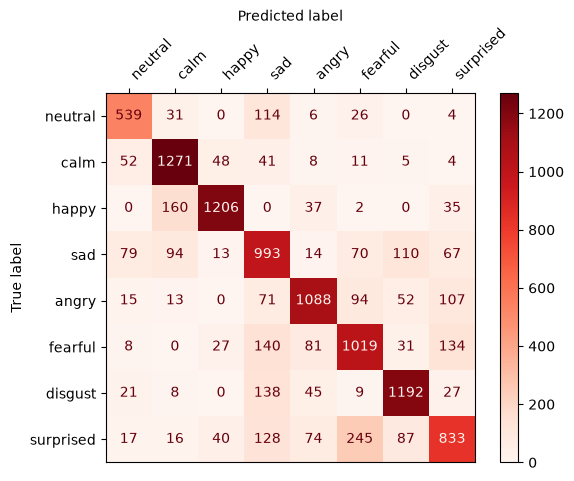

In [9]:
matrix_shuffle = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_shuffle, display_labels=labels_names)
matrix_shuffle.plot(cmap=plt.cm.Reds)

ax = matrix_shuffle.ax_
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top") 
ax.set_xticklabels(labels_names, rotation=45, ha="left")
plt.show()

### Conclusions
Over 30 stratified 70/30 splits, the pipeline reaches an accuracy of 0.754 with 0.023 std and a macro F1 of 0.752 with 0.023 std. The confusion matrix is summed over the 30 repetitions, the neutral row has half the counts of the others because neutral has 80 videos instead of 160. Macro F1 still gives it the same weight as every other class.

## 4.2 LOSO protocol

In [10]:
cv_group = LeaveOneGroupOut()
pipe_group = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf'))])

per_fold_results_group, predictions_group, conf_matrix_group = evl.evaluation(X, y, cv_group, pipe_group, groups)

### Mean & SD of Accuracy and Macro F1

In [11]:
results_group = per_fold_results_group[["accuracy", "macro_f1"]].agg(["mean", "std"])
results_group

,accuracy,macro_f1
mean,0.589167,0.557425
std,0.126731,0.145965


### Macro F1 Score per Held-out Actor

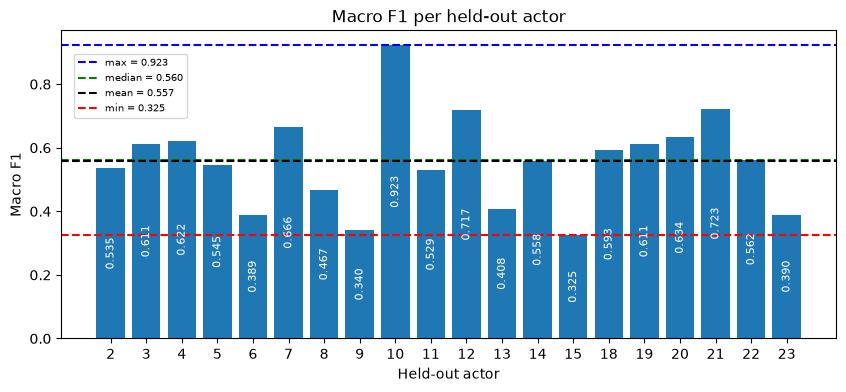

In [12]:
df_plot = per_fold_results_group.sort_values("held_out_actor")
mean_f1 = df_plot["macro_f1"].mean()
min_f1 = df_plot["macro_f1"].min()
median_f1 = df_plot["macro_f1"].median()
max_f1 = df_plot["macro_f1"].max()

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(df_plot["held_out_actor"].astype(str), df_plot["macro_f1"])
ax.bar_label(bars, fmt="%.3f", label_type="center", color="white", fontsize=8, rotation=90)
ax.axhline(max_f1, color="blue", linestyle="--", label=f"max = {max_f1:.3f}")
ax.axhline(median_f1, color="green", linestyle="--", label=f"median = {median_f1:.3f}")
ax.axhline(mean_f1, color="black", linestyle="--", label=f"mean = {mean_f1:.3f}")
ax.axhline(min_f1, color="red", linestyle="--", label=f"min = {min_f1:.3f}")
ax.set_xlabel("Held-out actor")
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 per held-out actor")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(0.01, 0.94))
plt.show()


### Confusion Matrix

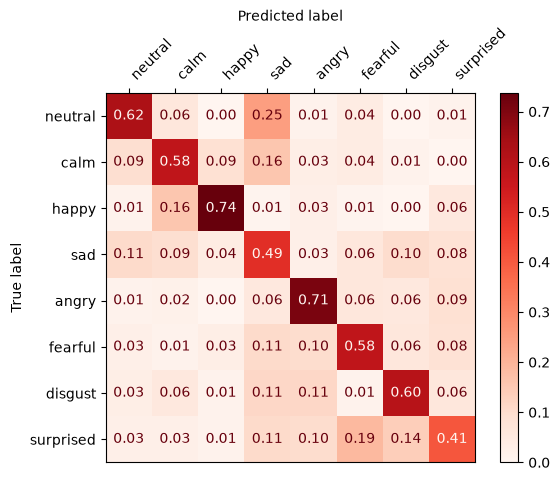

In [13]:
disp = ConfusionMatrixDisplay.from_predictions(
    predictions_group["y_true"],
    predictions_group["y_pred"],
    labels=np.unique(y),
    display_labels=labels_names,
    normalize="true",
    values_format=".2f",
    cmap=plt.cm.Reds,
)

ax = disp.ax_
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top") 
ax.set_xticklabels(labels_names, rotation=45, ha="left")
plt.show()

### Conclusions
Under LOSO, accuracy is 0.589 with 0.127 std and macro F1 is 0.557 with 0.146 std. The macro F1 per actor ranges from 0.325 (actor 15) to 0.923 (actor 10), with a median of 0.560. Actor 15 is the actor whose head bends down at the end of the videos (2.3), where the tracking is less reliable.

## 4.3 Random vs LOSO

### Confusion Matrix Comparison

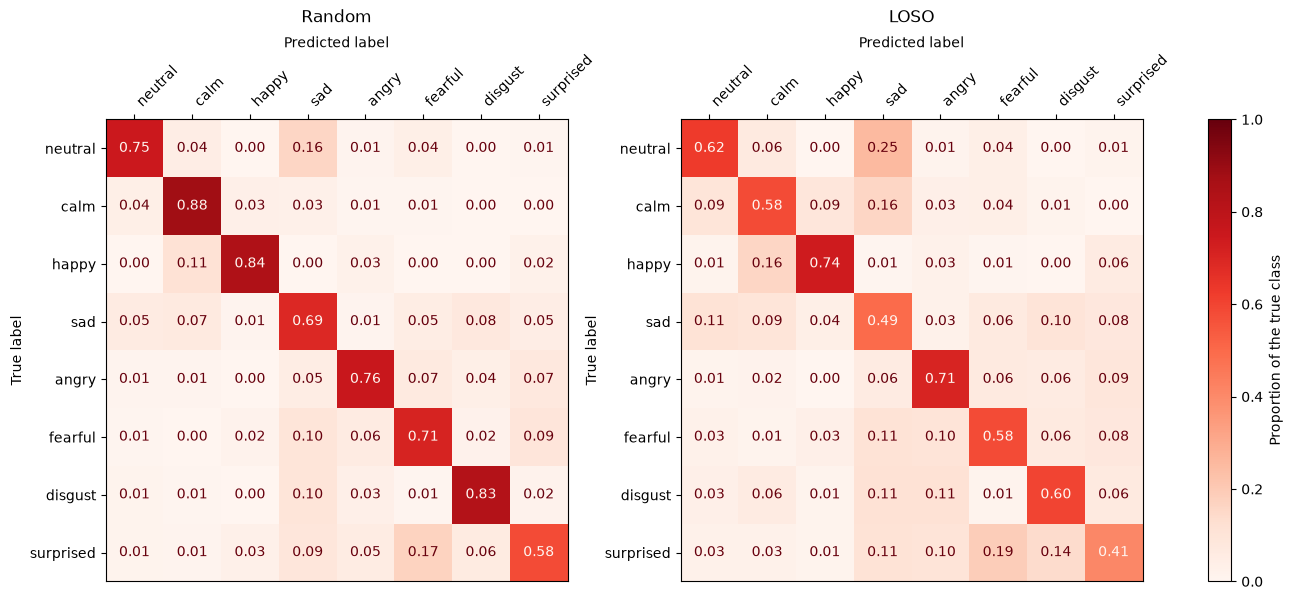

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

protocols = {"Random": predictions_shuffle,
             "LOSO": predictions_group}

for ax, (title, preds) in zip(axes, protocols.items()):
    disp = ConfusionMatrixDisplay.from_predictions(
        preds["y_true"],
        preds["y_pred"],
        labels=np.unique(y),
        display_labels=labels_names,
        normalize="true",
        values_format=".2f",
        cmap=plt.cm.Reds,
        colorbar=False,
        im_kw={"vmin": 0, "vmax": 1},
        ax=ax,
    )
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xticklabels(labels_names, rotation=45, ha="left")
    ax.set_title(title, pad=70)

fig.colorbar(disp.im_, ax=axes, label="Proportion of the true class")
plt.show()

### Comparison Table

In [20]:
protocols_table = pd.concat({"Random": results_shuffle, "LOSO": results_group}, axis=1)
protocols_table

Random                LOSO          
      accuracy  macro_f1  accuracy  macro_f1
mean  0.753796  0.752333  0.589167  0.557425
std   0.023383  0.022934  0.126731  0.145965

### Per-class Recall Comparison

In [16]:
recall_random = recall_score(predictions_shuffle["y_true"], 
                             predictions_shuffle["y_pred"],
                             labels=np.unique(y), 
                             average=None)

recall_loso = recall_score(predictions_group["y_true"], 
                           predictions_group["y_pred"],
                           labels=np.unique(y), 
                           average=None)

recall = pd.DataFrame({"Random": recall_random, 
                       "LOSO": recall_loso}, index=labels_names)

recall["Drop"] = recall["Random"] - recall["LOSO"]
recall.sort_values("LOSO").round(3)


,Random,LOSO,Drop
surprised,0.578,0.406,0.172
sad,0.690,0.494,0.196
fearful,0.708,0.581,0.126
calm,0.883,0.581,0.301
disgust,0.828,0.600,0.228
neutral,0.749,0.625,0.124
angry,0.756,0.706,0.049
happy,0.838,0.738,0.100


### Answer 4.3

| Protocol | Accuracy | Macro F1 |
|---|---|---|
| Random 70/30 (30 repetitions) | 0.754 ± 0.023 | 0.752 ± 0.023 |
| LOSO (20 actors) | 0.589 ± 0.127 | 0.557 ± 0.146 |

The random split answers to *"how well does the model recognise a new video of a person it has already seen?"*. LOSO answers to *"how well does it recognise the expressions of a person it has never seen?"*. Only LOSO estimates the performance on a new face.

Just like 1.3 stated, one row is one video, but the 60 videos of an actor are not independent. They share the same face shape, the same resting expression and the same way of acting. In a random split each actor has about 42 videos in training and 18 in test, so the model can learn each actor's own face and style, just like their usual mouth width or brow height and use it on their test videos. This is a leak of the actor's identity, and it raises the score by about 0.2 of macro F1. Under LOSO no actor appears in both sets, so this help disappears, hence the lower performance.

The per-class recall table supports this. The largest drop is *calm* (0.88 to 0.58): calm differs from neutral only slightly, relative to the actor's own resting face, so it can be recognised only when that face has been seen. The smallest drop is *angry* (0.76 to 0.71), whose frown and lowered brows look similar in every actor.

The standard deviations also mean different things. Under the random split (0.023) the 30 test sets overlap and each contains every actor, so the std only measures how much the score changes from one resampling to the next. Under LOSO (0.146) it measures how much the score changes from one person to another, from 0.325 (actor 15) to 0.923 (actor 10). This is real uncertainty about a new user.

The rest of the project must use LOSO.

## 4.4 Confusions under LOSO

### Classification Report

In [19]:
loso_report = classification_report(predictions_group["y_true"], predictions_group["y_pred"], target_names=labels_names)
print(loso_report)

              precision    recall  f1-score   support

     neutral       0.51      0.62      0.56        80
        calm       0.60      0.58      0.59       160
       happy       0.80      0.74      0.77       160
         sad       0.42      0.49      0.46       160
       angry       0.64      0.71      0.67       160
     fearful       0.60      0.58      0.59       160
     disgust       0.62      0.60      0.61       160
   surprised       0.52      0.41      0.46       160

    accuracy                           0.59      1200
   macro avg       0.59      0.59      0.59      1200
weighted avg       0.59      0.59      0.59      1200



### True vs Predicted Count 

In [21]:
counts = pd.DataFrame({"True count": predictions_group["y_true"].map(cfg.EMOTIONS).value_counts(),
                       "Predicted count": predictions_group["y_pred"].map(cfg.EMOTIONS).value_counts(),
                       }).reindex(labels_names, fill_value=0)

counts

,True count,Predicted count
neutral,80,99
calm,160,156
happy,160,147
sad,160,186
angry,160,177
fearful,160,155
disgust,160,155
surprised,160,125


### Top Confusions Table (top 5)

In [22]:
cm_norm = pd.DataFrame(conf_matrix_group / conf_matrix_group.sum(axis=1, keepdims=True),
                       index=labels_names, 
                       columns=labels_names)

off_diag = cm_norm.where(~np.eye(len(labels_names), dtype=bool))

top_confusions = (off_diag.stack()
                          .dropna()
                          .sort_values(ascending=False)
                          .head(5)
                          .rename_axis(["True", "Predicted"])
                          .reset_index(name="Rate"))

top_confusions["Reverse rate"] = [cm_norm.loc[p, t] for t, p in zip(top_confusions["True"], top_confusions["Predicted"])]
top_confusions.round(3)

,True,Predicted,Rate,Reverse rate
0,neutral,sad,0.250,0.106
1,surprised,fearful,0.188,0.081
2,happy,calm,0.156,0.088
3,calm,sad,0.156,0.094
4,surprised,disgust,0.138,0.062


### Answer 4.4

The most frequent confusions under LOSO (top 5) are seen in the table above of the cell above.

The pattern is mostly plausible given the measures of Table 2:

- **Neutral, calm and sad** are all low-movement expressions. What separates them is small: slightly downturned corners (M3) and lowered brows (M4) in sad. These differences are smaller than the differences between the resting faces of different actors, so without the actor's own neutral face to compare with they overlap. *Sad* acts as the default class for these quiet faces: it is predicted 186 times for 160 true videos and has the lowest precision (0.42).
- **Surprised predicted as fearful** both raise the brows (M4), widen the eyes (M5) and open the mouth (M1). What separates them is subtle: fear stretches the lips (M2) and draws the brows together (M6).
- **Happy predicted as calm**: when calm, a person often appears a slight smile, so it shares the smile measures (M2, M3) with happy at a lower level. Happy is still the best recognised class (F1 0.77), because a full smile is distinctive.
- **Surprised predicted as disgust** is less expected from Table 2. Table 2 does not measure the raised upper lip and the wrinkled nose of disgust (our own feature M10 targets the upper lip), and in both emotions the mouth opens. M1 measures how open the mouth is, not its shape.

These errors are not symmetric: neutral predicted as sad (0.25) is more than twice as frequent as sad predicted as neutral (0.11). The model leans towards some classes, not just mixing pairs equally.

**The hardest emotion is surprised**: it has the lowest recall (0.41) and is predicted only 125 times for 160 videos. Its videos are spread over fearful, disgust, sad and angry. By F1 it ties with sad (0.46), but for different reasons: surprised is missed, while sad is predicted too often. Possible reasons:

1. Surprise is a short expression, at the start of the clip, while the actor keeps speaking the sentence. The statistics of Table 3 are computed over about 3–4 s, so the mean is diluted by the frames after it fades.
2. Every video is speech, so the mouth measures (M1 and its velocity and energy) are dominated by talking. This hides the dropped jaw, the main mouth cue of surprise.
3. Its brow and eye cues (M4, M5) are shared with fear.

Surprised was also the worst class under the random split (0.58), so the difficulty comes from the features themselves, not only from the actor being unseen.
